8번째 코드

7번코드 + 증강데이터 적용

📊 Train Acc: 94.47% | Val Loss: 0.3503, Val Acc: 86.84%

🛑 조기 종료 발동. (Patience: 5)

✅ 학습 완료. 최종 무기 저장 경로: /workspace/user1/model_v6_binary_final/best_final_binary_filter.pth

In [2]:
#환경 설정 및 라이브러리 임포트

import os
# OpenCV의 불필요한 SOS 경고 로그를 차단합니다.
os.environ['OPENCV_LOG_LEVEL'] = 'ERROR'

import json
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import random

# ================= 설정 =================
# 1. 원본 데이터 경로
RAW_IMG_BASE = "/workspace/user1/dataset_v2/img/train" 
LBL_BASE = "/workspace/user1/dataset_v2/label_mod/train"
VAL_IMG_BASE = "/workspace/user1/dataset_v2/img/val"
VAL_LBL_BASE = "/workspace/user1/dataset_v2/label_mod/val"

# 2. 팀원 증강 데이터 경로 (Train에만 추가)
AUG_IMG_BASE = "/workspace/user5/img_augmented/train"

SAVE_DIR = '/workspace/user1/model_v6_binary_final'
os.makedirs(SAVE_DIR, exist_ok=True)

SEED = 42
BATCH_SIZE = 64
IMG_SIZE = 224
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# [핵심] 이진 분류용 다이렉트 매핑 (0: 감정있음, 1: 무표정)
# 팀원 데이터의 'blank'도 1로 매핑되도록 처리
BINARY_MAP = {
    'anger': 0, 'happy': 0, 'panic': 0, 'sadness': 0, 
    'neutral': 1, 'blank': 1
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"✅ 환경 설정 완료. 장치: {DEVICE}")

✅ 환경 설정 완료. 장치: cuda


In [3]:
# 최종 이진 분류 데이터셋 (원본 크롭 + 증강 통합)

class FinalBinaryDataset(Dataset):
    def __init__(self, raw_img_base, aug_img_base, lbl_base, transform=None, is_train=True):
        self.transform = transform
        self.samples = []
        
        neutral_count = 0
        emotion_count = 0

        # --- 1. 원본 데이터 (JSON 기반 크롭 필요) ---
        print(f"🔍 원본 데이터 로딩 중: {lbl_base}")
        if os.path.exists(lbl_base):
            for json_file in tqdm(os.listdir(lbl_base), desc="Loading JSONs", leave=False):
                if not json_file.endswith('.json'): continue
                with open(os.path.join(lbl_base, json_file), 'r', encoding='utf-8') as f:
                    data = json.load(f)
                    for item in data['images']:
                        if item.get('is_box_issue') == 'Yes': continue
                        
                        binary_label = BINARY_MAP[item['final_emotion']]
                        if binary_label == 1: neutral_count += 1
                        else: emotion_count += 1

                        self.samples.append({
                            'source': 'raw',
                            'img_path': os.path.join(raw_img_base, item['final_emotion'], item['filename']),
                            'bbox': item['bbox'],
                            'binary_label': binary_label
                        })

        # --- 2. 팀원 증강 데이터 (Train일 경우에만 추가) ---
        if is_train and os.path.exists(aug_img_base):
            print(f"🔍 증강 데이터 로딩 중: {aug_img_base}")
            for folder_name in BINARY_MAP.keys():
                src_folder = os.path.join(aug_img_base, folder_name)
                if not os.path.isdir(src_folder): continue
                
                binary_label = BINARY_MAP[folder_name]
                file_list = [f for f in os.listdir(src_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                
                for filename in file_list:
                    if binary_label == 1: neutral_count += 1
                    else: emotion_count += 1
                        
                    self.samples.append({
                        'source': 'aug',
                        'img_path': os.path.join(src_folder, filename),
                        'binary_label': binary_label
                    })

        print(f"✅ 로딩 완료. (Emotion[0]: {emotion_count}장 / Neutral[1]: {neutral_count}장)")

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        image = cv2.imread(item['img_path'])
        
        if image is None: return self.__getitem__(random.randint(0, len(self)-1))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # 원본 소스인 경우에만 크롭 수행 (증강 데이터는 이미 크롭되어 있음)
        if item['source'] == 'raw':
            box = item['bbox']
            x1, y1, x2, y2 = max(0, box['minX']), max(0, box['minY']), box['maxX'], box['maxY']
            if x2 <= x1 or y2 <= y1: return self.__getitem__(random.randint(0, len(self)-1))
            image = image[y1:y2, x1:x2]
            
        if self.transform:
            image = self.transform(image=image)['image']
            
        return image, torch.tensor(item['binary_label'], dtype=torch.long)

print("✅ FinalBinaryDataset 클래스 정의 완료.")

✅ FinalBinaryDataset 클래스 정의 완료.


In [4]:
# Transform 및 DataLoader 설정

# 증강 데이터가 이미 포함되어 있으므로, 실시간 증강은 가벼운 기하학적 변형만 유지합니다.
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# 증강 데이터는 Train 세트에만 포함
train_dataset = FinalBinaryDataset(RAW_IMG_BASE, AUG_IMG_BASE, LBL_BASE, transform=train_transform, is_train=True)
val_dataset = FinalBinaryDataset(VAL_IMG_BASE, AUG_IMG_BASE, VAL_LBL_BASE, transform=val_transform, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("⚡ DataLoader 설정 완료.")

/home/user1/.conda/envs/mwkim/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


🔍 원본 데이터 로딩 중: /workspace/user1/dataset_v2/label_mod/train


🔍 증강 데이터 로딩 중: /workspace/user5/img_augmented/train
✅ 로딩 완료. (Emotion[0]: 27525장 / Neutral[1]: 4141장)
🔍 원본 데이터 로딩 중: /workspace/user1/dataset_v2/label_mod/val


✅ 로딩 완료. (Emotion[0]: 1037장 / Neutral[1]: 126장)
⚡ DataLoader 설정 완료.


In [8]:
# 모델 로드 및 극단적 Loss 가중치 설정

def get_binary_model():
    model = timm.create_model('efficientnet_b2', pretrained=True, num_classes=2)
    fer_url = "https://github.com/sb-ai-lab/EmotiEffLib/raw/main/models/affectnet_emotions/enet_b2_8.pt"
    
    print("🚀 FER 전용 가중치 주입 중...")
    try:
        loaded = torch.hub.load_state_dict_from_url(fer_url, map_location='cpu', weights_only=False)
        if hasattr(loaded, 'state_dict'): loaded = loaded.state_dict()
        filtered_dict = {k: v for k, v in loaded.items() if 'classifier' not in k and 'head' not in k and 'fc' not in k}
        model.load_state_dict(filtered_dict, strict=False)
        print("✅ 가중치 주입 성공.")
    except Exception as e:
        print(f"⚠️ 주입 실패. 기본 가중치 사용. ({e})")
    return model

model = get_binary_model().to(DEVICE)

# [최종 무기] 놓친 50장을 잡기 위해 Neutral(1)의 패널티를 5.0으로 극단 상향
class_weights = torch.tensor([1.0, 3.8]).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)

print("✅ 모델 및 극단적 Loss 가중치 설정 완료.")

🚀 FER 전용 가중치 주입 중...
✅ 가중치 주입 성공.
✅ 모델 및 극단적 Loss 가중치 설정 완료.


In [9]:
# 최종 필터 모델 학습 루프

NUM_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
trigger_times = 0

SAVE_PATH = os.path.join(SAVE_DIR, 'best_final_binary_filter.pth')
scaler = torch.amp.GradScaler('cuda')

print("🚀 [최종 진화] 극장 증강 + 편향 가중치 이진 분류 학습 시작...")

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    train_pbar = tqdm(train_loader, desc=f"Ep [{epoch+1}/{NUM_EPOCHS}] Train")
    for images, labels in train_pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        train_pbar.set_postfix({'loss': f"{loss.item():.4f}"})

    train_loss = running_loss / len(train_dataset)
    train_acc = correct_train / total_train * 100

    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_dataset)
    val_acc = correct_val / total_val * 100
    
    scheduler.step(val_loss)

    print(f"📊 Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"  💾 성능 갱신! 모델 저장됨 (Val Loss: {val_loss:.4f})")
        trigger_times = 0
    else:
        trigger_times += 1
        if trigger_times >= PATIENCE:
            print(f"\n🛑 조기 종료 발동. (Patience: {PATIENCE})")
            break

print(f"\n✅ 학습 완료. 최종 무기 저장 경로: {SAVE_PATH}")

🚀 [최종 진화] 극장 증강 + 편향 가중치 이진 분류 학습 시작...


Ep [1/30] Train:   1%|          | 4/495 [00:05<07:05,  1.15it/s, loss=0.9838]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:   2%|▏         | 8/495 [00:10<06:41,  1.21it/s, loss=0.6545]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:   3%|▎         | 14/495 [00:17<08:12,  1.02s/it, loss=0.7018]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:   8%|▊         | 38/495 [00:43<09:11,  1.21s/it, loss=0.6026]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:  13%|█▎        | 62/495 [01:08<06:12,  1.16it/s, loss=0.6600]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:  29%|██▉       | 146/495 [02:37<03:45,  1.55it/s, loss=0.6307]Invalid SOS parameters for sequential JPEG
Invalid SOS param

📊 Train Acc: 76.02% | Val Loss: 0.4497, Val Acc: 83.06%
  💾 성능 갱신! 모델 저장됨 (Val Loss: 0.4497)


Ep [2/30] Train:   0%|          | 0/495 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   2%|▏         | 11/495 [00:12<06:00,  1.34it/s, loss=0.4384]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   2%|▏         | 12/495 [00:13<05:55,  1.36it/s, loss=0.4949]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   5%|▌         | 27/495 [00:28<05:45,  1.36it/s, loss=0.5581]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   6%|▌         | 28/495 [00:29<06:21,  1.22it/s, loss=0.4897]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:  11%|█         | 52/495 [00:52<06:14,  1.18it/s, loss=0.3092]Invalid SOS parameters for sequential 

📊 Train Acc: 81.26% | Val Loss: 0.3201, Val Acc: 84.52%
  💾 성능 갱신! 모델 저장됨 (Val Loss: 0.3201)


Ep [3/30] Train:   6%|▌         | 28/495 [00:27<04:18,  1.80it/s, loss=0.2578]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   6%|▋         | 32/495 [00:32<04:44,  1.63it/s, loss=0.6144]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   7%|▋         | 36/495 [00:35<04:25,  1.73it/s, loss=0.4209]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   8%|▊         | 40/495 [00:39<04:15,  1.78it/s, loss=0.4538]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   9%|▉         | 44/495 [00:43<04:32,  1.65it/s, loss=0.5047]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid 

... (15 outputs left out)

Ep [11/30] Train:   0%|          | 0/495 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [11/30] Train:   5%|▍         | 24/495 [00:25<04:46,  1.64it/s, loss=0.1163]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [11/30] Train:   9%|▊         | 43/495 [00:44<05:47,  1.30it/s, loss=0.1472]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [11/30] Train:  10%|█         | 51/495 [00:52<05:26,  1.36it/s, loss=0.1247]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [11/30] Train:  16%|█▌        | 79/495 [01:20<05:13,  1.33it/s, loss=0.1251]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [11/30] Train:  25%|██▌       | 124/495 [02:04<03:38,  1.70it/s, loss=0.1062]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequ

📊 Train Acc: 94.34% | Val Loss: 0.3385, Val Acc: 86.41%


Ep [12/30] Train:   0%|          | 0/495 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/30] Train:   2%|▏         | 12/495 [00:12<05:09,  1.56it/s, loss=0.3257]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/30] Train:   3%|▎         | 15/495 [00:16<06:23,  1.25it/s, loss=0.0560]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/30] Train:   6%|▋         | 32/495 [00:33<05:00,  1.54it/s, loss=0.1232]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/30] Train:   7%|▋         | 35/495 [00:37<05:59,  1.28it/s, loss=0.0426]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/30] Train:  13%|█▎        | 64/495 [01:05<04:26,  1.62it/s, loss=0.0797]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/30] Train:  17%|█▋       

📊 Train Acc: 94.47% | Val Loss: 0.3503, Val Acc: 86.84%

🛑 조기 종료 발동. (Patience: 5)

✅ 학습 완료. 최종 무기 저장 경로: /workspace/user1/model_v6_binary_final/best_final_binary_filter.pth


🚀 FER 전용 가중치 주입 중...
✅ 가중치 주입 성공.


Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS

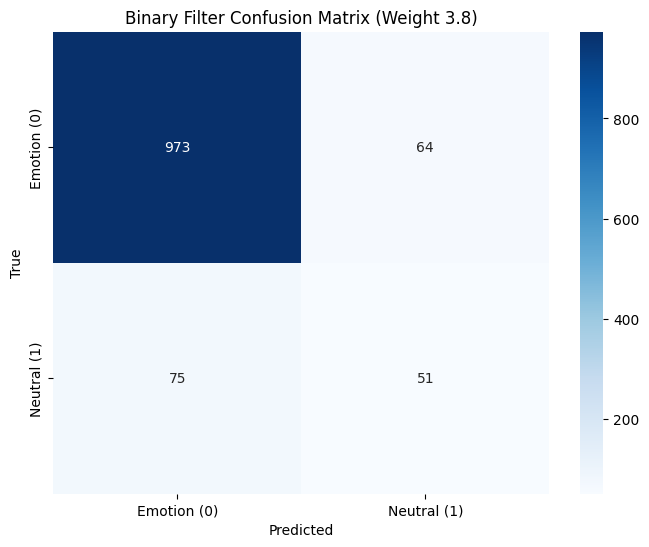

In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 버전 6(최종 이진 분류 모델) 로드
model = get_binary_model().to(DEVICE)
model.load_state_dict(torch.load('/workspace/user1/model_v6_binary_final/best_final_binary_filter.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            out = model(imgs)
        all_preds.extend(torch.max(out, 1)[1].cpu().numpy())
        all_labels.extend(lbls.numpy())

# 혼동 행렬 시각화
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Emotion (0)', 'Neutral (1)'],
            yticklabels=['Emotion (0)', 'Neutral (1)'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Binary Filter Confusion Matrix (Weight 3.8)')
plt.show()